**01. DATA UNDERSTANDING AND LOADING**

# 1.1 LOAD CSV,JSON,SQL FILE

In [47]:
import pandas as pd
import numpy as np

In [48]:
df_rider = pd.read_excel('/content/riders.xlsx')

In [49]:
df_trip = pd.read_json('/content/trips.json')

In [50]:
import sqlite3
with open("city_zones.sql", "r") as file:
    sql_lines = file.readlines()

cleaned_sql = "\n".join(
    line for line in sql_lines
    if not line.strip().lower().startswith(("create database", "use "))
)

cleaned_sql = cleaned_sql.replace("varchar(50) INTEGER", "INTEGER")

conn = sqlite3.connect(":memory:")
conn.executescript(cleaned_sql)

df_city_zones = pd.read_sql_query("SELECT * FROM city_zones", conn)

In [51]:
df_rider

,rider_id,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating
0,R0001,Aarav Das,23.0,Male,Pune,2020-06-29,56.0,0.0,3.76
1,R0002,Ishaan Nair,39.0,Female,Mumbai,2019-11-23,70.0,5.0,4.12
2,R0003,Kavya Reddy,34.0,Male,Pune,2023-05-04,45.0,9.0,3.76
3,R0004,Aarav Nair,19.0,Other,Kolkata,2019-07-28,464.0,5.0,3.19
4,R0005,Diya Reddy,27.0,Male,Ahmedabad,2021-05-31,294.0,30.0,3.53
...,...,...,...,...,...,...,...,...,...
295,R0296,Reyansh Patel,37.0,Other,Hyderabad,2021-02-20,390.0,58.0,3.97
296,R0297,Saanvi Gupta,47.0,Male,Pune,2023-09-20,396.0,46.0,3.87
297,R0298,Vivaan Singh,35.0,Female,Ahmedabad,2020-03-25,65.0,11.0,3.88
298,R0299,Ishaan Gupta,33.0,Other,Kolkata,2020-09-04,457.0,0.0,3.92


In [52]:
df_trip

,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag
0,T00001,R0037,Zone_10,11.83,74.59,104.88,Cash,2023-11-13,0
1,T00002,R0104,Zone_9,3.86,35.59,40.48,Cash,2023-07-28,1
2,T00003,R0045,Zone_8,4.70,31.03,46.39,Cash,2024-01-14,1
3,T00004,R0089,Zone_2,11.06,59.48,257.64,Cash,2023-12-13,0
4,T00005,R0003,Zone_5,7.28,67.59,72.74,UPI,2023-03-15,1
...,...,...,...,...,...,...,...,...,...
1995,T01996,R0171,Zone_6,0.91,6.44,22.12,UPI,2023-03-20,0
1996,T01997,R0287,Zone_5,11.40,103.03,193.75,Cash,2024-06-25,1
1997,T01998,R0254,Zone_9,4.94,39.32,58.45,Cash,2024-03-23,0
1998,T01999,R0267,Zone_2,7.76,51.43,74.92,UPI,2023-10-29,1


In [53]:
df_city_zones

,zone_name,population_density,traffic_index,avg_speed_kmph,zone_type
0,Zone_1,NaN,2.43,30.9,Residential
1,Zone_2,6371.0,0.91,58.4,Residential
2,Zone_3,12971.0,2.11,38.0,Business
3,Zone_4,4038.0,NaN,48.2,Business
4,Zone_5,2590.0,1.31,43.9,Business
5,Zone_6,NaN,0.54,37.6,Mixed
6,Zone_7,11070.0,0.64,NaN,Industrial
7,Zone_8,4516.0,1.93,31.0,Business
8,Zone_9,11037.0,NaN,56.1,Mixed
9,Zone_10,2440.0,1.54,NaN,Industrial


**info summary**

In [54]:
df_rider.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   rider_id         300 non-null    object        
 1   name             300 non-null    object        
 2   age              297 non-null    float64       
 3   gender           300 non-null    object        
 4   city             300 non-null    object        
 5   signup_date      300 non-null    datetime64[ns]
 6   total_rides      298 non-null    float64       
 7   cancelled_rides  298 non-null    float64       
 8   avg_rating       300 non-null    float64       
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 21.2+ KB


In [55]:
df_trip.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   trip_id       2000 non-null   object 
 1   rider_id      2000 non-null   object 
 2   zone          2000 non-null   object 
 3   distance_km   2000 non-null   float64
 4   duration_min  2000 non-null   float64
 5   fare_amount   2000 non-null   float64
 6   payment_mode  2000 non-null   object 
 7   ride_date     2000 non-null   object 
 8   surge_flag    2000 non-null   int64  
dtypes: float64(3), int64(1), object(5)
memory usage: 140.8+ KB


In [56]:
df_city_zones.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   zone_name           10 non-null     object 
 1   population_density  8 non-null      float64
 2   traffic_index       8 non-null      float64
 3   avg_speed_kmph      8 non-null      float64
 4   zone_type           10 non-null     object 
dtypes: float64(3), object(2)
memory usage: 532.0+ bytes


**FIRST 5 ROWS HEAD**

In [57]:
df_rider.head(5)


,rider_id,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating
0,R0001,Aarav Das,23.0,Male,Pune,2020-06-29,56.0,0.0,3.76
1,R0002,Ishaan Nair,39.0,Female,Mumbai,2019-11-23,70.0,5.0,4.12
2,R0003,Kavya Reddy,34.0,Male,Pune,2023-05-04,45.0,9.0,3.76
3,R0004,Aarav Nair,19.0,Other,Kolkata,2019-07-28,464.0,5.0,3.19
4,R0005,Diya Reddy,27.0,Male,Ahmedabad,2021-05-31,294.0,30.0,3.53


In [58]:
df_trip.head(5)

,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag
0,T00001,R0037,Zone_10,11.83,74.59,104.88,Cash,2023-11-13,0
1,T00002,R0104,Zone_9,3.86,35.59,40.48,Cash,2023-07-28,1
2,T00003,R0045,Zone_8,4.70,31.03,46.39,Cash,2024-01-14,1
3,T00004,R0089,Zone_2,11.06,59.48,257.64,Cash,2023-12-13,0
4,T00005,R0003,Zone_5,7.28,67.59,72.74,UPI,2023-03-15,1


In [59]:
df_city_zones.head(5)

,zone_name,population_density,traffic_index,avg_speed_kmph,zone_type
0,Zone_1,NaN,2.43,30.9,Residential
1,Zone_2,6371.0,0.91,58.4,Residential
2,Zone_3,12971.0,2.11,38.0,Business
3,Zone_4,4038.0,NaN,48.2,Business
4,Zone_5,2590.0,1.31,43.9,Business


**MISSING VALES COUNT**

In [60]:
df_rider.isnull().sum()

,0
rider_id,0
name,0
age,3
gender,0
city,0
signup_date,0
total_rides,2
cancelled_rides,2
avg_rating,0


In [61]:
df_trip.isnull().sum()

,0
trip_id,0
rider_id,0
zone,0
distance_km,0
duration_min,0
fare_amount,0
payment_mode,0
ride_date,0
surge_flag,0


In [62]:
df_city_zones.isnull().sum()

,0
zone_name,0
population_density,2
traffic_index,2
avg_speed_kmph,2
zone_type,0


**CHECK FOR DUPLICATES**

In [63]:
df_rider.duplicated().sum()

np.int64(0)

In [64]:
df_trip.duplicated().sum()

np.int64(0)

In [65]:
df_city_zones.duplicated().sum()

np.int64(0)

# check invalid entries

In [66]:
df_rider[df_rider['age']<10]

,rider_id,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating


In [67]:
df_trip[df_trip['distance_km'] < 0]

,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag


In [68]:
(df_trip['distance_km'] < 0).sum()

np.int64(0)

**2/ DATA CLEANING**

# handle numeric missing values using simple imputer(mean)

In [69]:
from sklearn.impute import SimpleImputer
df_rider=pd.read_excel('/content/riders.xlsx')

print ('BEFORE IMPUTATION:')
print(df_rider.isnull().sum())

imputer = SimpleImputer(strategy="mean")
df_rider["age"] = imputer.fit_transform(df_rider[["age"]])

print ('AFTER IMPUTATION:')
print(df_rider.isnull().sum())

BEFORE IMPUTATION:
rider_id           0
name               0
age                3
gender             0
city               0
signup_date        0
total_rides        2
cancelled_rides    2
avg_rating         0
dtype: int64
AFTER IMPUTATION:
rider_id           0
name               0
age                0
gender             0
city               0
signup_date        0
total_rides        2
cancelled_rides    2
avg_rating         0
dtype: int64


# handle numeric missing values using simple imputer(most_frequent) strategy

In [70]:

print ('BEFORE IMPUTATION:')
print(df_rider.isnull().sum())

imputer = SimpleImputer(strategy="most_frequent")
df_rider[["total_rides","cancelled_rides"]] = imputer.fit_transform(df_rider[["total_rides","cancelled_rides"]])

print ('AFTER IMPUTATION:')
print(df_rider.isnull().sum())

BEFORE IMPUTATION:
rider_id           0
name               0
age                0
gender             0
city               0
signup_date        0
total_rides        2
cancelled_rides    2
avg_rating         0
dtype: int64
AFTER IMPUTATION:
rider_id           0
name               0
age                0
gender             0
city               0
signup_date        0
total_rides        0
cancelled_rides    0
avg_rating         0
dtype: int64


# convert incosistent date fromats

In [71]:
df_rider =pd.read_excel('/content/riders.xlsx')
print("BEFORE IMPUTATION:")

print(df_rider['signup_date'].head(10))
df_rider['signup_date']=pd.to_datetime(df_rider['signup_date'], format='mixed',dayfirst=True,errors='coerce')

print('AFTER IMPUTATIONS:')
print(df_rider['signup_date'].head(10))


BEFORE IMPUTATION:
0   2020-06-29
1   2019-11-23
2   2023-05-04
3   2019-07-28
4   2021-05-31
5   2023-06-30
6   2021-03-26
7   2022-10-01
8   2019-12-15
9   2023-05-14
Name: signup_date, dtype: datetime64[ns]
AFTER IMPUTATIONS:
0   2020-06-29
1   2019-11-23
2   2023-05-04
3   2019-07-28
4   2021-05-31
5   2023-06-30
6   2021-03-26
7   2022-10-01
8   2019-12-15
9   2023-05-14
Name: signup_date, dtype: datetime64[ns]


●	Remove unrealistic entries:
○	Negative fare
○	Zero-distance ride but billed
________________________________________


In [72]:
print('NEGATIVE FARE ENTRIES:')
print(df_trip[df_trip['fare_amount']< 0])


print("=======================================")


print("ZERO DISTANCE BUT BILLED ENTRIES:")
print(df_trip[df_trip['distance_km']< 0])

NEGATIVE FARE ENTRIES:
Empty DataFrame
Columns: [trip_id, rider_id, zone, distance_km, duration_min, fare_amount, payment_mode, ride_date, surge_flag]
Index: []
ZERO DISTANCE BUT BILLED ENTRIES:
Empty DataFrame
Columns: [trip_id, rider_id, zone, distance_km, duration_min, fare_amount, payment_mode, ride_date, surge_flag]
Index: []


**3  OUTLIERS HANDLING**

# ●	Use Z-score method to detect fare & distance anomalies.

In [73]:
from scipy.stats import zscore

df_trip['fare_amount_zscore'] = zscore(df_trip['fare_amount'])
df_trip['distance_km_zscore'] = zscore(df_trip['distance_km'])

fare_outliers = df_trip[abs(df_trip['fare_amount_zscore']) > 3]
distance_outliers = df_trip[abs(df_trip['distance_km_zscore']) > 3]

df_trip_cleaned = df_trip[
    (df_trip['fare_amount_zscore'].abs() <= 3) &
    (df_trip['distance_km_zscore'].abs() <= 3)
].copy()

df_trip_cleaned.drop(
    columns=['fare_amount_zscore', 'distance_km_zscore'],
    inplace=True
)

print("Original dataset shape:", df_trip.shape)
print("Cleaned dataset shape:", df_trip_cleaned.shape)


Original dataset shape: (2000, 11)
Cleaned dataset shape: (1981, 9)


# ●	Use IQR method for ride duration anomalies.

In [74]:
Q1 = df_trip['duration_min'].quantile(0.25)
Q3 = df_trip['duration_min'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_trip[
    (df_trip['duration_min'] < lower_limit) |
    (df_trip['duration_min'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Duration Anomalies:", len(outliers))

outliers[['trip_id', 'duration_min']]

Q1: 35.415
Q3: 85.375
IQR: 49.96
Lower Limit: -39.525
Upper Limit: 160.315
Number of Duration Anomalies: 18


,trip_id,duration_min
57,T00058,161.83
185,T00186,173.85
290,T00291,164.64
343,T00344,161.82
425,T00426,167.72
431,T00432,178.53
550,T00551,190.53
754,T00755,165.01
1064,T01065,184.53
1168,T01169,160.35


# ●	Apply Winsorization where necessary (e.g., extreme surge fares).

In [75]:
from scipy.stats.mstats import winsorize

print("Before Winsorization:")
print(df_trip['fare_amount'].describe())

df_trip['fare_amount_winsorized'] = winsorize(df_trip['fare_amount'],
    limits=[0.05, 0.05]
)

print("\nAfter Winsorization:")
print(df_trip['fare_amount_winsorized'].describe())

# Select surge rides
surge_mask = df_trip_cleaned['surge_flag'] == 1

# Apply Winsorization only to surge fares
df_trip_cleaned.loc[surge_mask, 'fare_amount'] = winsorize(
    df_trip_cleaned.loc[surge_mask, 'fare_amount'],
    limits=[0.05, 0.05]
)

print("Winsorization applied to surge fares.")
print(df_trip_cleaned[['fare_amount', 'surge_flag']].head())

Before Winsorization:
count    2000.000000
mean      134.600375
std        85.521989
min         0.250000
25%        70.440000
50%       121.850000
75%       182.867500
max       472.290000
Name: fare_amount, dtype: float64

After Winsorization:
count    2000.000000
mean      132.731120
std        78.900429
min        17.390000
25%        70.440000
50%       121.850000
75%       182.867500
max       297.220000
Name: fare_amount_winsorized, dtype: float64
Winsorization applied to surge fares.
   fare_amount  surge_flag
0       104.88           0
1        40.48           1
2        46.39           1
3       257.64           0
4        72.74           1


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4809: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


# Provide before vs after comparison.

In [76]:
from types import new_class
A={"befor(z_score(fare_amount))":df_trip.shape,
   "After(z_score(fare_amount))":df_trip_cleaned.shape,
   "befor(z_score(distance_km))":df_trip.shape,
   "After(z_score(distance_km))":df_trip_cleaned.shape,
   "befor(IQR)":df_trip.shape,
   "After(IQR)":df_trip_cleaned.shape,
   "befor_winsorization":df_trip.shape,
   "After_winsorization":df_trip_cleaned.shape}

B=pd.DataFrame(A,index=["Rows","columns"])
B.T

,Rows,columns
befor(z_score(fare_amount)),2000,12
After(z_score(fare_amount)),1981,9
befor(z_score(distance_km)),2000,12
After(z_score(distance_km)),1981,9
befor(IQR),2000,12
After(IQR),1981,9
befor_winsorization,2000,12
After_winsorization,1981,9


**✅ 4. Data Transformation**
# ●	Convert datetime → hour, day_of_week, month

In [77]:
df_trip["ride_date"]=pd.to_datetime(df_trip["ride_date"])
df_trip["ride_hour"]=df_trip["ride_date"].dt.hour
df_trip["ride_day_of_week"]=df_trip["ride_date"].dt.dayofweek
df_trip["ride_month"]=df_trip["ride_date"].dt.month
display(df_trip[["ride_date", "ride_hour", "ride_day_of_week", "ride_month"]].head())

,ride_date,ride_hour,ride_day_of_week,ride_month
0,2023-11-13,0,0,11
1,2023-07-28,0,4,7
2,2024-01-14,0,6,1
3,2023-12-13,0,2,12
4,2023-03-15,0,2,3


# **●	Encode categorical columns:**
○	Label Encode: gender


In [78]:
from sklearn.preprocessing import LabelEncoder
df_rider=df_rider.copy()

le = LabelEncoder()

df_rider["gender"] = le.fit_transform(df_rider["gender"].astype(str))
df_rider["gender"]


,gender
0,1
1,0
2,1
3,2
4,1
...,...
295,2
296,1
297,0
298,2


# ○	One-Hot Encode: ride_payment_mode, zone_name

In [79]:
df_zones = df_city_zones.copy()

median_traffic = df_zones['traffic_index'].median()
filled_traffic = df_zones['traffic_index'].fillna(median_traffic)

df_zones['traffic_level'] = pd.cut(
    filled_traffic,
    bins=[-float('inf'), 1, 2, float('inf')],
    labels=['Low', 'Medium', 'High']
)

df_zones['traffic_level_encoded'] = pd.cut(
    filled_traffic,
    bins=[-float('inf'), 1, 2, float('inf')],
    labels=[0, 1, 2]
).astype(int)

df_zones

,zone_name,population_density,traffic_index,avg_speed_kmph,zone_type,traffic_level,traffic_level_encoded
0,Zone_1,NaN,2.43,30.9,Residential,High,2
1,Zone_2,6371.0,0.91,58.4,Residential,Low,0
2,Zone_3,12971.0,2.11,38.0,Business,High,2
3,Zone_4,4038.0,NaN,48.2,Business,Medium,1
4,Zone_5,2590.0,1.31,43.9,Business,Medium,1
5,Zone_6,NaN,0.54,37.6,Mixed,Low,0
6,Zone_7,11070.0,0.64,NaN,Industrial,Low,0
7,Zone_8,4516.0,1.93,31.0,Business,Medium,1
8,Zone_9,11037.0,NaN,56.1,Mixed,Medium,1
9,Zone_10,2440.0,1.54,NaN,Industrial,Medium,1


# ●	Binning:
# ○	Customer ride frequency (Low/Med/High)

In [80]:
ride_counts = df_trip_cleaned.groupby('rider_id')['trip_id'].count()

def categorize_frequency(count):
    if count <= 2:
        return 'Low'
    elif count <= 5:
        return 'Medium'
    else:
        return 'High'

df_trip_cleaned['ride_frequency'] = df_trip_cleaned['rider_id'].map(ride_counts)

df_trip_cleaned['ride_frequency_category'] = df_trip_cleaned['ride_frequency'].apply(
    categorize_frequency
)

print(df_trip_cleaned[['rider_id', 'ride_frequency', 'ride_frequency_category']].head(20))

   rider_id  ride_frequency ride_frequency_category
0     R0037               8                    High
1     R0104               9                    High
2     R0045               9                    High
3     R0089               9                    High
4     R0003              10                    High
5     R0255               8                    High
6     R0224               7                    High
7     R0039               7                    High
8     R0223               8                    High
9     R0236              11                    High
10    R0191              11                    High
11    R0199              10                    High
12    R0248               7                    High
13    R0300               6                    High
14    R0270               8                    High
15    R0216               5                  Medium
16    R0168               5                  Medium
17    R0126               6                    High
18    R0255 

In [81]:
print(df_trip_cleaned['ride_frequency_category'].value_counts())

ride_frequency_category
High      1551
Medium     415
Low         15
Name: count, dtype: int64


# **●	Transform skewed numeric columns:**
○	Log transform on fare and distance


In [82]:
df_trip_cleaned["fare_amount"] = np.log(df_trip_cleaned["fare_amount"])
df_trip_cleaned["distance_km"] = np.log(df_trip_cleaned["distance_km"])
print(df_trip_cleaned[["fare_amount", "distance_km"]].head())

   fare_amount  distance_km
0     4.652817     2.470639
1     3.700808     1.350667
2     3.837084     1.547563
3     5.551563     2.403335
4     4.286891     1.985131


**○ Square-root transform on duration**

In [83]:
df_trip_cleaned['duration_sqrt'] = np.sqrt(df_trip_cleaned["duration_min"])

df_trip_cleaned['duration_sqrt']

,duration_sqrt
0,8.636550
1,5.965735
2,5.570458
3,7.712328
4,8.221314
...,...
1995,2.537716
1996,10.150369
1997,6.270566
1998,7.171471


**Feature Scaling**
# ●	Scale numeric features using:
# ○	StandardScaler
# ○	MinMaxScaler


In [84]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

numeric_features = [
    'distance_km',
    'duration_min',
    'fare_amount']

df_scaled = df_trip.copy()
standard_scaler = StandardScaler()

df_scaled[[col + '_standard' for col in numeric_features]] = (
    standard_scaler.fit_transform(df_scaled[numeric_features]))
minmax_scaler = MinMaxScaler()

df_scaled[[col + '_minmax' for col in numeric_features]] = (
    minmax_scaler.fit_transform(df_scaled[numeric_features])
)

print("Feature Scaling Results:")
print(df_scaled.head())

print("\nComparison:")
print(df_scaled[
    ['distance_km', 'distance_km_standard', 'distance_km_minmax',
     'duration_min', 'duration_min_standard', 'duration_min_minmax',
     'fare_amount', 'fare_amount_standard', 'fare_amount_minmax']
].head())

Feature Scaling Results:
  trip_id rider_id     zone  distance_km  duration_min  fare_amount payment_mode  ride_date  surge_flag  fare_amount_zscore  distance_km_zscore  fare_amount_winsorized  ride_hour  ride_day_of_week  ride_month  distance_km_standard  duration_min_standard  fare_amount_standard  distance_km_minmax  duration_min_minmax  fare_amount_minmax
0  T00001    R0037  Zone_10        11.83         74.59       104.88         Cash 2023-11-13           0           -0.347604            0.805112                  104.88          0                 0          11              0.805112               0.353239             -0.353079            0.457043             0.370370            0.312654
1  T00002    R0104   Zone_9         3.86         35.59        40.48         Cash 2023-07-28           1           -1.100815           -0.985983                   40.48          0                 4           7             -0.985983              -0.730949             -1.169502            0.148607      

**● Show before vs after stats (mean/std/min/max)**

In [85]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)


print('********** Riders Data (After Encoding Gender) **********')
print(df_rider.describe(include='all').round(2))


print('********** Zones Data (Before Binning/Imputation) **********')
print(df_city_zones.describe(include='all').round(2))


print('********** Zones Data (After Binning/Imputation) **********')
print(df_zones.describe(include='all').round(2))

********** Riders Data (After Encoding Gender) **********
       rider_id        name     age  gender    city          signup_date  total_rides  cancelled_rides  avg_rating
count       300         300  297.00  300.00     300                  300       298.00           298.00      300.00
unique      300          96     NaN     NaN      10                  NaN          NaN              NaN         NaN
top       R0300  Aarav Nair     NaN     NaN  Mumbai                  NaN          NaN              NaN         NaN
freq          1           8     NaN     NaN      35                  NaN          NaN              NaN         NaN
mean        NaN         NaN   31.54    0.95     NaN  2021-05-23 06:57:36       244.52            22.83        3.99
min         NaN         NaN   18.00    0.00     NaN  2019-01-01 00:00:00         4.00             0.00        3.00
25%         NaN         NaN   26.00    0.00     NaN  2020-03-04 00:00:00       110.25             7.00        3.55
50%         NaN       

**✅ 6. Feature Construction**

In [86]:

df_features = df_trip_cleaned.copy()

# Convert date column to datetime
df_features['ride_date'] = pd.to_datetime(
    df_features['ride_date']
)

# 1. Average Ride Distance per Customer
df_features['avg_ride_distance'] = (
    df_features.groupby('rider_id')['distance_km']
    .transform('mean')
)

# 2. Average Ride Fare per Customer
df_features['avg_ride_fare'] = (
    df_features.groupby('rider_id')['fare_amount']
    .transform('mean')
)

# 3. Days Since Signup

if 'signup_date' in df_features.columns:
    df_features['signup_date'] = pd.to_datetime(
        df_features['signup_date'], errors='coerce'
    )
    today = pd.Timestamp.today().normalize()
    df_features['days_since_signup'] = (
        today - df_features['signup_date']
    ).dt.days

# 4. Peak Hour Feature

if (
    df_features['ride_date'].notna().any()
    and (
        df_features['ride_date'].dt.hour.ne(0).any()
    )
):
    hour = df_features['ride_date'].dt.hour
    df_features['is_peak_hour'] = (
        hour.between(7, 9) | hour.between(18, 21)
    ).astype(int)

# 5. Ride Cancellation Rate

if 'ride_status' in df_features.columns:
    df_features['is_cancelled'] = (
        df_features['ride_status'].str.lower() == 'cancelled'
    ).astype(int)

    df_features['ride_cancellation_rate'] = (
        df_features.groupby('rider_id')['is_cancelled']
        .transform('mean')
    )

# 6. Surge Flag based on Fare per Kilometre
df_features['fare_per_km'] = np.where(
    df_features['distance_km'] > 0,
    df_features['fare_amount'] / df_features['distance_km'],
    np.nan
)

threshold = df_features['fare_per_km'].quantile(0.90)

df_features['surge_flag'] = (
    df_features['fare_per_km'] > threshold
).astype(int)

# Display constructed features
print("Feature Construction Completed!")
print(df_features.head())

print("\nNew Dataset Shape:", df_features.shape)
print("\nAvailable Columns:")
print(df_features.columns.tolist())


Feature Construction Completed!
  trip_id rider_id     zone  distance_km  duration_min  fare_amount payment_mode  ride_date  surge_flag  ride_frequency ride_frequency_category  duration_sqrt  avg_ride_distance  avg_ride_fare  fare_per_km
0  T00001    R0037  Zone_10     2.470639         74.59     4.652817         Cash 2023-11-13           0               8                    High       8.636550           2.145831       4.923796     1.883245
1  T00002    R0104   Zone_9     1.350667         35.59     3.700808         Cash 2023-07-28           0               9                    High       5.965735           1.268283       4.014569     2.739985
2  T00003    R0045   Zone_8     1.547563         31.03     3.837084         Cash 2024-01-14           0               9                    High       5.570458           2.189645       4.942784     2.479437
3  T00004    R0089   Zone_2     2.403335         59.48     5.551563         Cash 2023-12-13           0               9                    High 

**### . Final Dataset**
#●	Merge cleaned & enriched datasets


In [87]:
# ============================================
# 1. MERGE CLEANED & ENRICHED DATASETS
# ============================================

# Start with the enriched dataset
df_final = df_features.copy()

# Merge rider information
if 'rider_id' in df_final.columns and 'rider_id' in df_rider.columns:
    rider_columns = [
        col for col in df_rider.columns
        if col != 'rider_id' and col not in df_final.columns
    ]

    df_final = df_final.merge(
        df_rider[['rider_id'] + rider_columns],
        on='rider_id',
        how='left'
    )

# Merge city zone information if a common key exists
if 'zone' in df_final.columns and 'zone_name' in df_city_zones.columns:
    zone_columns = [
        col for col in df_city_zones.columns
        if col != 'zone_name' and col not in df_final.columns
    ]

    df_final = df_final.merge(
        df_city_zones[['zone_name'] + zone_columns],
        left_on='zone',
        right_on='zone_name',
        how='left'
    )

    df_final.drop(columns=['zone_name'], inplace=True)

print("Dataset Merge Completed!")
print("Final Dataset Shape:", df_final.shape)
print("\nFinal Dataset Columns:")
print(df_final.columns.tolist())

display(df_final.head())


Dataset Merge Completed!
Final Dataset Shape: (1981, 27)

Final Dataset Columns:
['trip_id', 'rider_id', 'zone', 'distance_km', 'duration_min', 'fare_amount', 'payment_mode', 'ride_date', 'surge_flag', 'ride_frequency', 'ride_frequency_category', 'duration_sqrt', 'avg_ride_distance', 'avg_ride_fare', 'fare_per_km', 'name', 'age', 'gender', 'city', 'signup_date', 'total_rides', 'cancelled_rides', 'avg_rating', 'population_density', 'traffic_index', 'avg_speed_kmph', 'zone_type']


,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag,ride_frequency,ride_frequency_category,duration_sqrt,avg_ride_distance,avg_ride_fare,fare_per_km,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating,population_density,traffic_index,avg_speed_kmph,zone_type
0,T00001,R0037,Zone_10,2.470639,74.59,4.652817,Cash,2023-11-13,0,8,High,8.636550,2.145831,4.923796,1.883245,Aadhya Iyer,32.0,2,Ahmedabad,2020-11-21,489.0,6.0,3.36,2440.0,1.54,NaN,Industrial
1,T00002,R0104,Zone_9,1.350667,35.59,3.700808,Cash,2023-07-28,0,9,High,5.965735,1.268283,4.014569,2.739985,Diya Gupta,52.0,1,Kolkata,2021-05-27,NaN,1.0,3.70,11037.0,NaN,56.1,Mixed
2,T00003,R0045,Zone_8,1.547563,31.03,3.837084,Cash,2024-01-14,0,9,High,5.570458,2.189645,4.942784,2.479437,Saanvi Iyer,34.0,2,Ahmedabad,2023-07-12,100.0,16.0,4.88,4516.0,1.93,31.0,Business
3,T00004,R0089,Zone_2,2.403335,59.48,5.551563,Cash,2023-12-13,0,9,High,7.712328,2.023687,4.789602,2.309942,Saanvi Reddy,48.0,2,Surat,2022-09-21,308.0,6.0,3.91,6371.0,0.91,58.4,Residential
4,T00005,R0003,Zone_5,1.985131,67.59,4.286891,UPI,2023-03-15,0,10,High,8.221314,1.464512,4.108275,2.159501,Kavya Reddy,34.0,1,Pune,2023-05-04,45.0,9.0,3.76,2590.0,1.31,43.9,Business


**produce final summar**y

In [88]:
# ============================================
# 2. FINAL DATASET SUMMARY TABLE
# ============================================

# Rows before and after cleaning
rows_before = len(df_trip)
rows_after = len(df_trip_cleaned)

# Missing values before and after cleaning
missing_before = int(df_trip.isnull().sum().sum())
missing_after = int(df_trip_cleaned.isnull().sum().sum())

# Count outliers using IQR method for duration
Q1 = df_trip['duration_min'].quantile(0.25)
Q3 = df_trip['duration_min'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_before = int(
    (
        (df_trip['duration_min'] < lower_limit) |
        (df_trip['duration_min'] > upper_limit)
    ).sum()
)

outliers_after = int(
    (
        (df_trip_cleaned['duration_min'] < lower_limit) |
        (df_trip_cleaned['duration_min'] > upper_limit)
    ).sum()
)

# Count newly engineered features
new_features = [
    col for col in df_features.columns
    if col not in df_trip.columns
]

# Create summary table
summary_table = pd.DataFrame({
    'Metric': [
        'Rows',
        'Missing Values',
        'Duration Outliers (IQR)',
        'New Engineered Features'
    ],
    'Before': [
        rows_before,
        missing_before,
        outliers_before,
        0
    ],
    'After': [
        rows_after,
        missing_after,
        outliers_after,
        len(new_features)
    ]
})

print("FINAL DATA PREPARATION SUMMARY")
display(summary_table)

print("\nNew Engineered Features:")
print(new_features)

print("\nFinal Dataset Shape:", df_final.shape)


FINAL DATA PREPARATION SUMMARY


,Metric,Before,After
0,Rows,2000,1981
1,Missing Values,0,0
2,Duration Outliers (IQR),18,8
3,New Engineered Features,0,6



New Engineered Features:
['ride_frequency', 'ride_frequency_category', 'duration_sqrt', 'avg_ride_distance', 'avg_ride_fare', 'fare_per_km']

Final Dataset Shape: (1981, 27)


In [89]:
# Display final dataset information

print("Final Dataset Information:")
print("Rows:", df_final.shape[0])
print("Columns:", df_final.shape[1])

print("\nMissing Values:")
print(df_final.isnull().sum())

print("\nFirst 5 Rows:")
display(df_final.head())

# Save the final dataset
df_final.to_csv(
    "final_ride_demand_dataset.csv",
    index=False
)

print("\nFinal dataset saved successfully!")


Final Dataset Information:
Rows: 1981
Columns: 27

Missing Values:
trip_id                      0
rider_id                     0
zone                         0
distance_km                  0
duration_min                 0
fare_amount                  0
payment_mode                 0
ride_date                    0
surge_flag                   0
ride_frequency               0
ride_frequency_category      0
duration_sqrt                0
avg_ride_distance            0
avg_ride_fare                0
fare_per_km                 95
name                         0
age                         25
gender                       0
city                         0
signup_date                  0
total_rides                 19
cancelled_rides             15
avg_rating                   0
population_density         419
traffic_index              394
avg_speed_kmph             387
zone_type                    0
dtype: int64

First 5 Rows:


,trip_id,rider_id,zone,distance_km,duration_min,fare_amount,payment_mode,ride_date,surge_flag,ride_frequency,ride_frequency_category,duration_sqrt,avg_ride_distance,avg_ride_fare,fare_per_km,name,age,gender,city,signup_date,total_rides,cancelled_rides,avg_rating,population_density,traffic_index,avg_speed_kmph,zone_type
0,T00001,R0037,Zone_10,2.470639,74.59,4.652817,Cash,2023-11-13,0,8,High,8.636550,2.145831,4.923796,1.883245,Aadhya Iyer,32.0,2,Ahmedabad,2020-11-21,489.0,6.0,3.36,2440.0,1.54,NaN,Industrial
1,T00002,R0104,Zone_9,1.350667,35.59,3.700808,Cash,2023-07-28,0,9,High,5.965735,1.268283,4.014569,2.739985,Diya Gupta,52.0,1,Kolkata,2021-05-27,NaN,1.0,3.70,11037.0,NaN,56.1,Mixed
2,T00003,R0045,Zone_8,1.547563,31.03,3.837084,Cash,2024-01-14,0,9,High,5.570458,2.189645,4.942784,2.479437,Saanvi Iyer,34.0,2,Ahmedabad,2023-07-12,100.0,16.0,4.88,4516.0,1.93,31.0,Business
3,T00004,R0089,Zone_2,2.403335,59.48,5.551563,Cash,2023-12-13,0,9,High,7.712328,2.023687,4.789602,2.309942,Saanvi Reddy,48.0,2,Surat,2022-09-21,308.0,6.0,3.91,6371.0,0.91,58.4,Residential
4,T00005,R0003,Zone_5,1.985131,67.59,4.286891,UPI,2023-03-15,0,10,High,8.221314,1.464512,4.108275,2.159501,Kavya Reddy,34.0,1,Pune,2023-05-04,45.0,9.0,3.76,2590.0,1.31,43.9,Business



Final dataset saved successfully!


# Handle missing numerical values using median

In [90]:


numeric_cols = df_final.select_dtypes(include='number').columns

df_final[numeric_cols] = df_final[numeric_cols].fillna(
    df_final[numeric_cols].median()
)

print("Missing values after imputation:")
print(df_final.isnull().sum().sum())

Missing values after imputation:
0


In [93]:
# Export Final Dataset

print("Final dataset exported successfully!")
print("Dataset Shape:", df_final.shape)



Final dataset exported successfully!
Dataset Shape: (1981, 27)


**auto generate pandas /ydata profiling eda \\**

In [95]:
!pip install -q ydata-profiling
from ydata_profiling import ProfileReport

# Generate EDA report
profile = ProfileReport(
    df_final,
    title="Ride Demand Forecasting - EDA Report",
    explorative=True
)

# Save report as HTML
profile.to_file("ride_demand_eda_report.html")

print("EDA Report Generated Successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.9 MB/s eta 0:00:00


/tmp/ipykernel_2340/3014610886.py:2: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 27/27 [00:00<00:00, 48.22it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

EDA Report Generated Successfully!


**   Visualization**

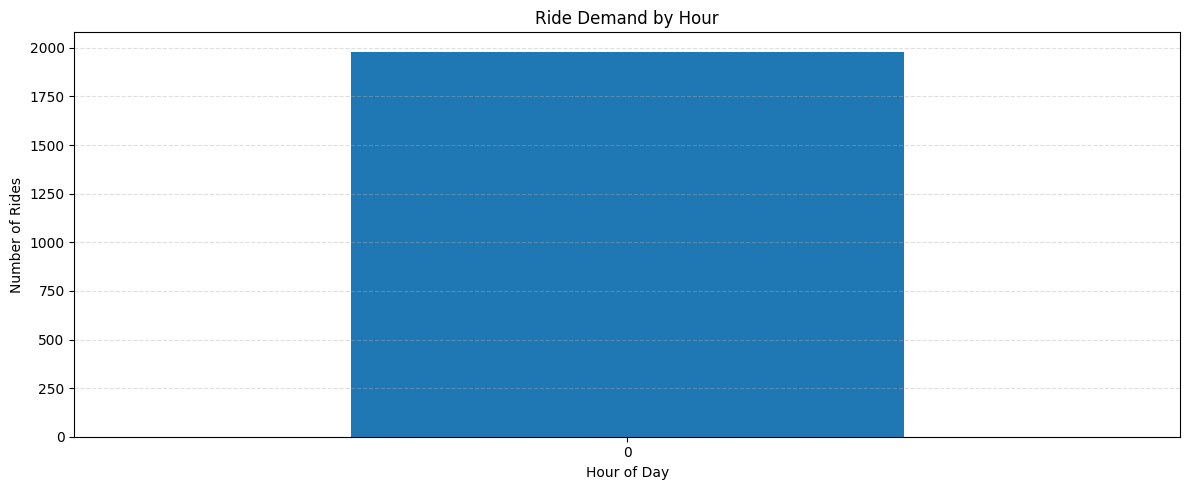

In [98]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert ride_date timestamp to datetime
df_final['ride_date'] = pd.to_datetime(
    df_final['ride_date'],
    errors='coerce'
)

# Extract hour
df_final['hour'] = df_final['ride_date'].dt.hour

# Count rides by hour
hourly_demand = df_final.groupby('hour')['trip_id'].count()

# Plot
plt.figure(figsize=(12, 5))
hourly_demand.plot(kind='bar')

plt.title('Ride Demand by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Rides')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

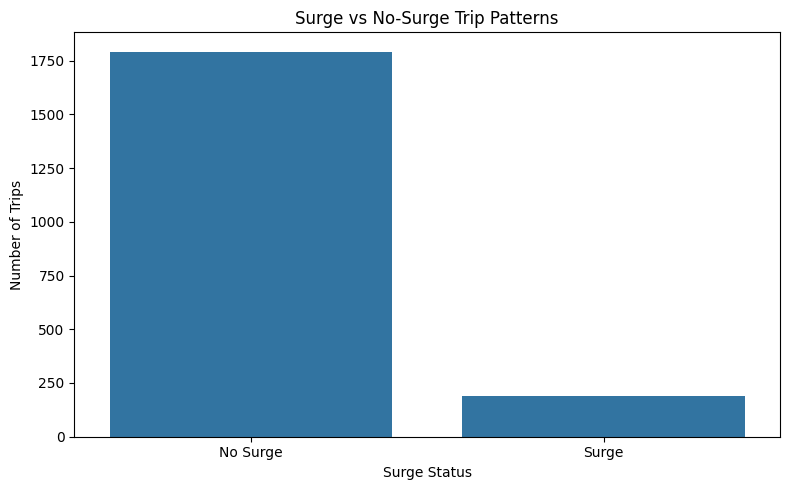

Trip Counts:
surge_status
No Surge    1792
Surge        189
Name: count, dtype: int64


In [99]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert surge flag into readable labels
df_final['surge_status'] = df_final['surge_flag'].map({
    0: 'No Surge',
    1: 'Surge'
})

# Count trips
surge_counts = df_final['surge_status'].value_counts()

# Plot
plt.figure(figsize=(8, 5))

sns.barplot(
    x=surge_counts.index,
    y=surge_counts.values
)

plt.title('Surge vs No-Surge Trip Patterns')
plt.xlabel('Surge Status')
plt.ylabel('Number of Trips')
plt.tight_layout()
plt.show()

# Display counts
print("Trip Counts:")
print(surge_counts)
